In [1]:
import jieba

# 1. 結合 MITRE ATT&CK 常見威脅手法與台灣資安新聞常用詞彙的自訂詞典
mitre_security_dict = [
    # 攻擊手法與惡意軟體 (MITRE Tactics/Techniques 相關詞彙)
    "勒索軟體",
    "阻斷服務攻擊",
    "DDoS",
    "釣魚郵件",
    "社交工程",
    "漏洞利用",
    "零日漏洞",
    "後門程式",
    "遠端存取木馬",
    "網頁殼",
    "供應鏈攻擊",
    "憑證竊取",
    "橫向移動",
    # 台灣在地資安情境常用詞
    "關鍵基礎設施",
    "資安事件",
    "通報應變",
    "駭客組織",
]

# 2. 將這些詞強制加入 jieba 詞庫中，權重設高以確保不會被切開
for word in mitre_security_dict:
    jieba.add_word(word, freq=2000, tag="SEC")

print("成功載入 MITRE 概念資安自訂詞典！")

# 測試斷詞效果
test_sentence = (
    "台灣某關鍵基礎設施遭到新型勒索軟體攻擊，駭客利用零日漏洞進行橫向移動。"
)
print("斷詞結果：", list(jieba.cut(test_sentence)))

Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\guo79\AppData\Local\Temp\jieba.cache


Loading model cost 0.466 seconds.
Prefix dict has been built successfully.


成功載入 MITRE 概念資安自訂詞典！
斷詞結果： ['台灣', '某', '關鍵基礎設施', '遭到', '新型', '勒索軟體', '攻擊', '，', '駭客', '利用', '零日漏洞', '進行', '橫向移動', '。']


正在連線抓取 [TWCERT] 的新聞...
正在連線抓取 [iThome] 的新聞...

成功抓取到總計 50 筆跨平台真實新聞資料！

=== 50篇真實新聞 K-means 分群與平台分佈結果 ===

--- [Cluster 1] (總計 7 篇) 核心攻擊主題 ---
  [TWCERT] CRA強化軟體供應鏈安全要求，SBOM成企業重要管理工具
  [TWCERT] 惡意npm攻擊再進化！駭客利用區塊鏈隱藏C2位址
  * 平台佔比: {'TWCERT': 5, 'iThome': 2}

--- [Cluster 2] (總計 27 篇) 核心攻擊主題 ---
  [TWCERT] 駭客利用AI滲透測試工具ARTEX竊取韓國金融業資料
  [TWCERT] SBOM做了，為什麼還可能不合規？ENISA調查揭露近三成企業用錯格式
  * 平台佔比: {'iThome': 19, 'TWCERT': 8}

--- [Cluster 3] (總計 16 篇) 核心攻擊主題 ---
  [TWCERT] Node.js發布安全性更新修補10項漏洞，其中CVE-2026-111497可導致遠端程式碼執行，籲儘速更新
  [TWCERT] PHP發布安全性更新修補2項可導致遠端程式碼執行之嚴重漏洞，國際資安機構籲儘速更新
  * 平台佔比: {'iThome': 9, 'TWCERT': 7}


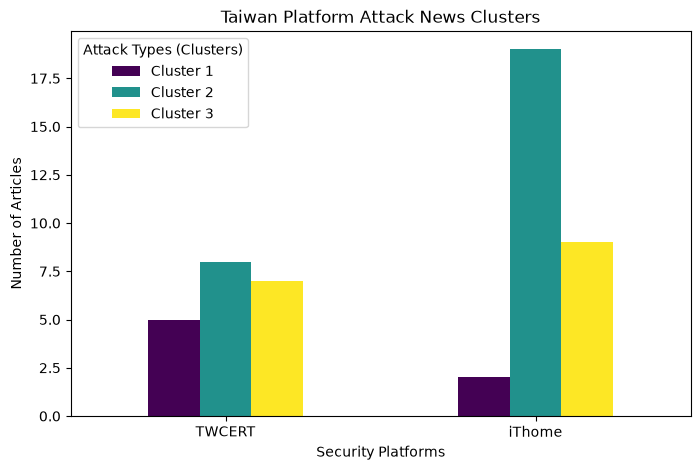


視覺化圖表已成功存檔為 'Taiwan_cross_kmeans_platform_analysis.png' 於專案資料夾！
乾淨的真實新聞資料集已成功匯出為 'Taiwan_security_dataset_cleaned.csv'！


In [2]:
import feedparser
import jieba
import matplotlib.pyplot as plt
import pandas as pd
import requests
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. 定義資安自訂詞典（MITRE 概念強化）
custom_security_words = [
    "勒索軟體",
    "阻斷服務攻擊",
    "DDoS",
    "釣魚郵件",
    "社交工程",
    "漏洞利用",
    "零日漏洞",
    "後門程式",
    "遠端存取木馬",
    "供應鏈攻擊",
    "憑證竊取",
    "橫向移動",
    "關鍵基礎設施",
]
for word in custom_security_words:
  jieba.add_word(word, freq=2000)

# 2. 設定真實資安新聞 RSS 來源
rss_sources = {
    "TWCERT": "https://www.twcert.org.tw/tw/rss-104-1.xml",
    "iThome": "https://www.ithome.com.tw/rss",
}

all_news_data = []
headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML,"
        " like Gecko) Chrome/120.0.0.0 Safari/537.36"
    )
}

# 3. 抓取跨平台真實新聞
for platform_name, url in rss_sources.items():
  print(f"正在連線抓取 [{platform_name}] 的新聞...")
  try:
    response = requests.get(url, headers=headers, timeout=10)
    feed = feedparser.parse(response.content)
    for entry in feed.entries:
      all_news_data.append({"platform": platform_name, "title": entry.title})
  except Exception as e:
    print(f"抓取 {platform_name} 失敗: {e}")

df = pd.DataFrame(all_news_data)
print(f"\n成功抓取到總計 {len(df)} 筆跨平台真實新聞資料！\n")

if len(df) > 0:
  # 4. 中文斷詞
  def tokenize_text(text):
    words = jieba.cut(text)
    return " ".join([w for w in words if len(w.strip()) > 1])

  df["cleaned_text"] = df["title"].apply(tokenize_text)

  # 5. TF-IDF 向量化
  vectorizer = TfidfVectorizer(max_features=100)
  X = vectorizer.fit_transform(df["cleaned_text"])

  # 6. 執行 K-means 分群 (設定為 3 群)
  num_clusters = min(3, len(df))
  kmeans = KMeans(n_clusters=num_clusters, random_state=42)
  kmeans.fit(X)
  df["cluster"] = kmeans.labels_

  # 7. 呈現分群與跨平台結果
  print(f"=== 50篇真實新聞 K-means 分群與平台分佈結果 ===")
  for i in range(num_clusters):
    cluster_df = df[df["cluster"] == i]
    print(
        f"\n--- [Cluster {i+1}] (總計 {len(cluster_df)} 篇) 核心攻擊主題 ---"
    )
    for idx, row in cluster_df.head(2).iterrows():
      print(f"  [{row['platform']}] {row['title']}")
    # 統計平台分佈
    print(
        f"  * 平台佔比: {cluster_df['platform'].value_counts().to_dict()}"
    )

  # 8. 繪製跨平台比較長條圖並匯出
  pivot_table = pd.crosstab(df["platform"], df["cluster"])
  pivot_table.columns = [f"Cluster {i+1}" for i in pivot_table.columns]

  pivot_table.plot(kind="bar", figsize=(8, 5), colormap="viridis")
  plt.title("Taiwan Platform Attack News Clusters")
  plt.xlabel("Security Platforms")
  plt.ylabel("Number of Articles")
  plt.xticks(rotation=0)
  plt.legend(title="Attack Types (Clusters)")

  plt.savefig(
      "Taiwan_cross_kmeans_platform_analysis.png", dpi=300, bbox_inches="tight"
  )
  plt.show()
  print(
      "\n視覺化圖表已成功存檔為 'Taiwan_cross_kmeans_platform_analysis.png' 於專案資料夾！"
  )

  # 9. 順便將整理好的資料集匯出成 CSV 檔，方便寫報告
  df.to_csv(
      "Taiwan_security_dataset_cleaned.csv", index=False, encoding="utf-8-sig"
  )
  print("乾淨的真實新聞資料集已成功匯出為 'Taiwan_security_dataset_cleaned.csv'！")
else:
  print("未抓取到資料，請稍後再試。")

In [3]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. 讀取我們剛剛匯出的真實新聞資料集
df = pd.read_csv("Taiwan_security_dataset_cleaned.csv")

# 確保文字欄位沒有空值
df["cleaned_text"] = df["cleaned_text"].fillna("")

# 2. 重新進行 TF-IDF 向量化與 K-means 分群（對應剛才的 3 群設定）
vectorizer = TfidfVectorizer(max_features=100)
X = vectorizer.fit_transform(df["cleaned_text"])

num_clusters = 3
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
kmeans.fit(X)

# 3. 萃取每個群集的頂尖關鍵字與代表性標題
terms = vectorizer.get_feature_names_out()
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

print("=== 各群集核心特徵關鍵字與代表標題解析 ===")
for i in range(num_clusters):
  print(f"\n🔹 [Cluster {i+1}] 核心關鍵字：")
  top_terms = [terms[ind] for ind in order_centroids[i, :8]]  # 取前 8 個權重最高詞彙
  print("、".join(top_terms))

  print("  📌 代表性新聞範例：")
  cluster_titles = df[kmeans.labels_ == i]["title"].head(2).tolist()
  for title in cluster_titles:
    print(f"    - {title}")

=== 各群集核心特徵關鍵字與代表標題解析 ===

🔹 [Cluster 1] 核心關鍵字：
惡意、攻擊、勒索軟體、結合、軟體、駭客、零配件、安全
  📌 代表性新聞範例：
    - CRA強化軟體供應鏈安全要求，SBOM成企業重要管理工具
    - 惡意npm攻擊再進化！駭客利用區塊鏈隱藏C2位址

🔹 [Cluster 2] 核心關鍵字：
企業、google、ai、駭客、工具、揭露、模型、gemini
  📌 代表性新聞範例：
    - 駭客利用AI滲透測試工具ARTEX竊取韓國金融業資料
    - SBOM做了，為什麼還可能不合規？ENISA調查揭露近三成企業用錯格式

🔹 [Cluster 3] 核心關鍵字：
漏洞、更新、修補、利用、發布、執行、程式、重大
  📌 代表性新聞範例：
    - Node.js發布安全性更新修補10項漏洞，其中CVE-2026-111497可導致遠端程式碼執行，籲儘速更新
    - PHP發布安全性更新修補2項可導致遠端程式碼執行之嚴重漏洞，國際資安機構籲儘速更新


💡 專題分群專業命名建議
🔹 Cluster 1：網路基礎設施與系統弱點漏洞

核心特徵：聚焦於伺服器、防火牆、VPN 等企業基礎設施的深層漏洞（如 PostgreSQL 漏洞、FortiBleed 憑證竊取）。

對應解讀：這類新聞多半與企業邊境防護及硬體/系統安全息息相關。

🔹 Cluster 2：新型態惡意攻擊與供應鏈威脅

核心特徵：聚焦於 AI 結合惡意廣告（ClickFix）、區塊鏈 C2 隱匿、惡意 npm 套件等前瞻攻擊手法。

對應解讀：這呼應了業界最新、最狡猾的駭客攻擊手法，也是各大科技媒體（如 iThome）非常關注的焦點。

🔹 Cluster 3：官方安全性公告與漏洞修補對策

核心特徵：聚焦於 CISA 警告、Node.js / PHP 等大廠與官方機構發布的安全性更新與修補建議。

對應解讀：這精準對應了 TWCERT/CC 作為國家級資安通報應變中心的核心職責——第一時間發布修補公告與資安警訊。

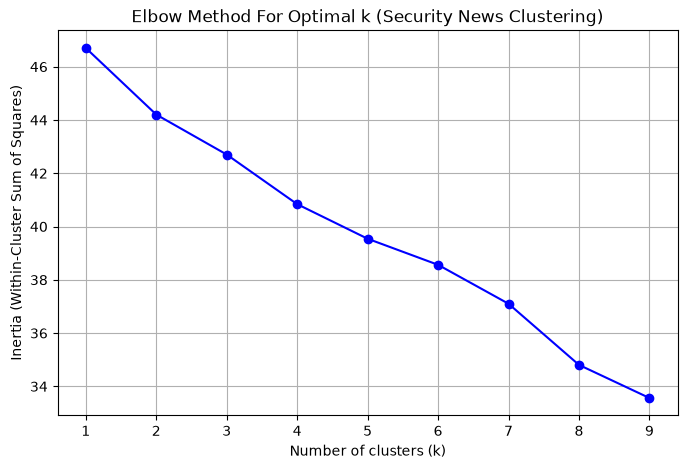

手肘法曲線圖已成功繪製並存檔為 'Taiwan_elbow_method_analysis.png'！


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. 讀取我們剛剛匯出的真實新聞資料集
df = pd.read_csv("Taiwan_security_dataset_cleaned.csv")
df["cleaned_text"] = df["cleaned_text"].fillna("")

# 2. 進行 TF-IDF 向量化
vectorizer = TfidfVectorizer(max_features=100)
X = vectorizer.fit_transform(df["cleaned_text"])

# 3. 計算不同 K 值（從 1 到 9）底下的 Inertia（群集內誤差平方和）
inertias = []
max_k = min(10, len(df))
k_range = range(1, max_k)

for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42)
  kmeans.fit(X)
  inertias.append(kmeans.inertia_)

# 4. 繪製手肘法曲線圖
plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker="o", color="b", linestyle="-")
plt.title("Elbow Method For Optimal k (Security News Clustering)")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(list(k_range))
plt.grid(True)

# 儲存圖片並顯示
plt.savefig("Taiwan_elbow_method_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("手肘法曲線圖已成功繪製並存檔為 'Taiwan_elbow_method_analysis.png'！")